# Notebook 10 — Model Evaluation and Comparison

**Purpose:** Comprehensive comparison of all models across all required metrics. Identify best models by different criteria. Generate comparison visualisations.

**Inputs:** Tuned OOF and test predictions from Notebook 09

**Outputs:**
- Complete comparison table (`results/metrics/10_full_comparison.csv`)
- Comparison visualisations (`results/figures/10_*.png`)


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.calibration import calibration_curve
from sklearn.preprocessing import label_binarize

from src.config import *
from src.evaluation import compute_all_metrics, metrics_to_dataframe, print_confusion_matrix
from src.plotting import (
    plot_confusion_matrix, plot_roc_curves, plot_pr_curves,
    plot_metric_comparison, save_figure, CLASS_NAMES, CLASS_COLOURS,
)

seed_everything()

# Load tuned OOF predictions
oof_df = pd.read_csv(os.path.join(RESULTS_METRICS, "09_tuned_oof_predictions.csv"))
y_true = oof_df["y_true"].values

MODEL_NAMES = ["LogisticRegression", "DecisionTree", "RandomForest",
               "SVM", "XGBoost", "LightGBM", "CatBoost"]
print(f"Models: {len(MODEL_NAMES)}")
print(f"Samples: {len(oof_df):,}")


Models: 7
Samples: 202,944


## 10.1 Complete Metric Comparison

In [2]:
all_metrics = []
for name in MODEL_NAMES:
    pred = oof_df[f"{name}_pred"].values
    prob = oof_df[[f"{name}_prob_{c}" for c in range(N_CLASSES)]].values
    met = compute_all_metrics(y_true, pred, prob, name)
    all_metrics.append(met)

metrics_df = metrics_to_dataframe(all_metrics)
metrics_df.to_csv(os.path.join(RESULTS_METRICS, "10_full_comparison.csv"))

# Display
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
print("Full OOF Comparison:")
print(metrics_df.round(4).to_string())


Full OOF Comparison:
                    Accuracy  Macro_Precision  Macro_Recall  Macro_F1  Balanced_Accuracy     MCC  Precision_Class0  Recall_Class0  F1_Class0  Precision_Class1  Recall_Class1  F1_Class1  Precision_Class2  Recall_Class2  F1_Class2  ROC_AUC_OVR  PR_AUC  Log_Loss  Brier_Score
Model                                                                                                                                                                                                                                                                           
LogisticRegression    0.6420           0.4487        0.5202    0.4275             0.5202  0.2949            0.9512         0.6586     0.7783            0.0299         0.3177     0.0547            0.3650         0.5843     0.4493       0.7734  0.4662    0.8802       0.1628
DecisionTree          0.5795           0.4311        0.4924    0.3938             0.4924  0.2551            0.9521         0.5838     0.7238            0.0248  

## 10.2 Best Models by Criterion

In [3]:
# Identify best models
print("\nBest Models by Criterion:")
print("=" * 50)
criteria = {
    "Best Overall (Macro F1)": "Macro_F1",
    "Best Accuracy": "Accuracy",
    "Best Balanced Accuracy": "Balanced_Accuracy",
    "Best MCC": "MCC",
    "Best ROC-AUC": "ROC_AUC_OVR",
    "Best PR-AUC": "PR_AUC",
    "Lowest Log Loss": "Log_Loss",
}

for label, col in criteria.items():
    if col in metrics_df.columns:
        if col == "Log_Loss":
            best = metrics_df[col].idxmin()
            val = metrics_df.loc[best, col]
        else:
            best = metrics_df[col].idxmax()
            val = metrics_df.loc[best, col]
        print(f"  {label}: {best} ({val:.4f})")

# Per-class best
for cls in range(N_CLASSES):
    col = f"Recall_Class{cls}"
    if col in metrics_df.columns:
        best = metrics_df[col].idxmax()
        val = metrics_df.loc[best, col]
        print(f"  Best Recall for {CLASS_MAP[cls]}: {best} ({val:.4f})")



Best Models by Criterion:
  Best Overall (Macro F1): SVM (0.4417)
  Best Accuracy: XGBoost (0.8421)
  Best Balanced Accuracy: LogisticRegression (0.5202)
  Best MCC: RandomForest (0.3261)
  Best ROC-AUC: LogisticRegression (0.7734)
  Best PR-AUC: CatBoost (0.4664)
  Lowest Log Loss: XGBoost (0.4361)
  Best Recall for No Diabetes: XGBoost (0.9640)
  Best Recall for Prediabetes: LogisticRegression (0.3177)
  Best Recall for Diabetes: RandomForest (0.7093)


## 10.3 Comparison Visualisations

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\10_key_metrics_comparison.png


<Figure size 1680x720 with 0 Axes>

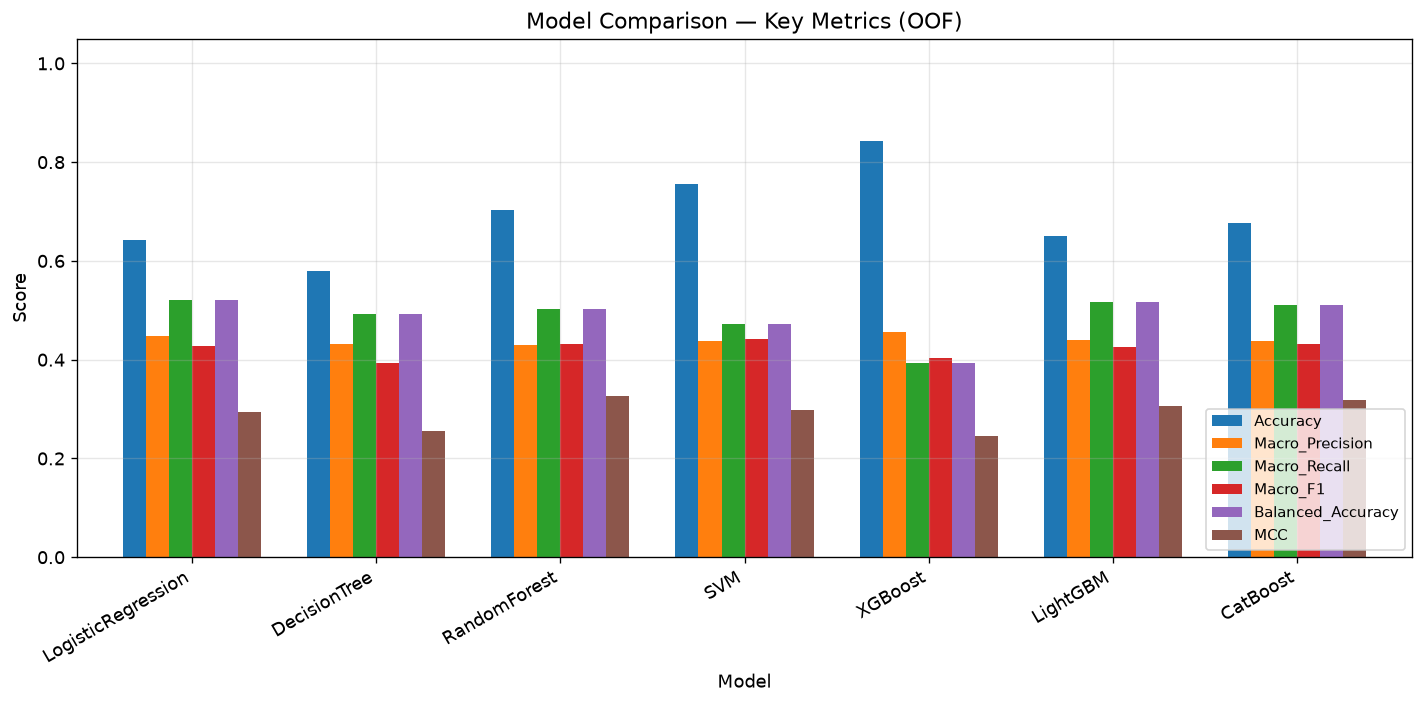

In [4]:
# Grouped bar chart
fig = plt.figure(figsize=(14, 6))
ax = plot_metric_comparison(
    metrics_df,
    metrics_to_plot=["Accuracy", "Macro_Precision", "Macro_Recall", "Macro_F1",
                     "Balanced_Accuracy", "MCC"],
    title="Model Comparison — Key Metrics (OOF)"
)
save_figure(plt.gcf(), os.path.join(RESULTS_FIGURES, "10_key_metrics_comparison.png"))
plt.show()


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\10_roc_all_models.png


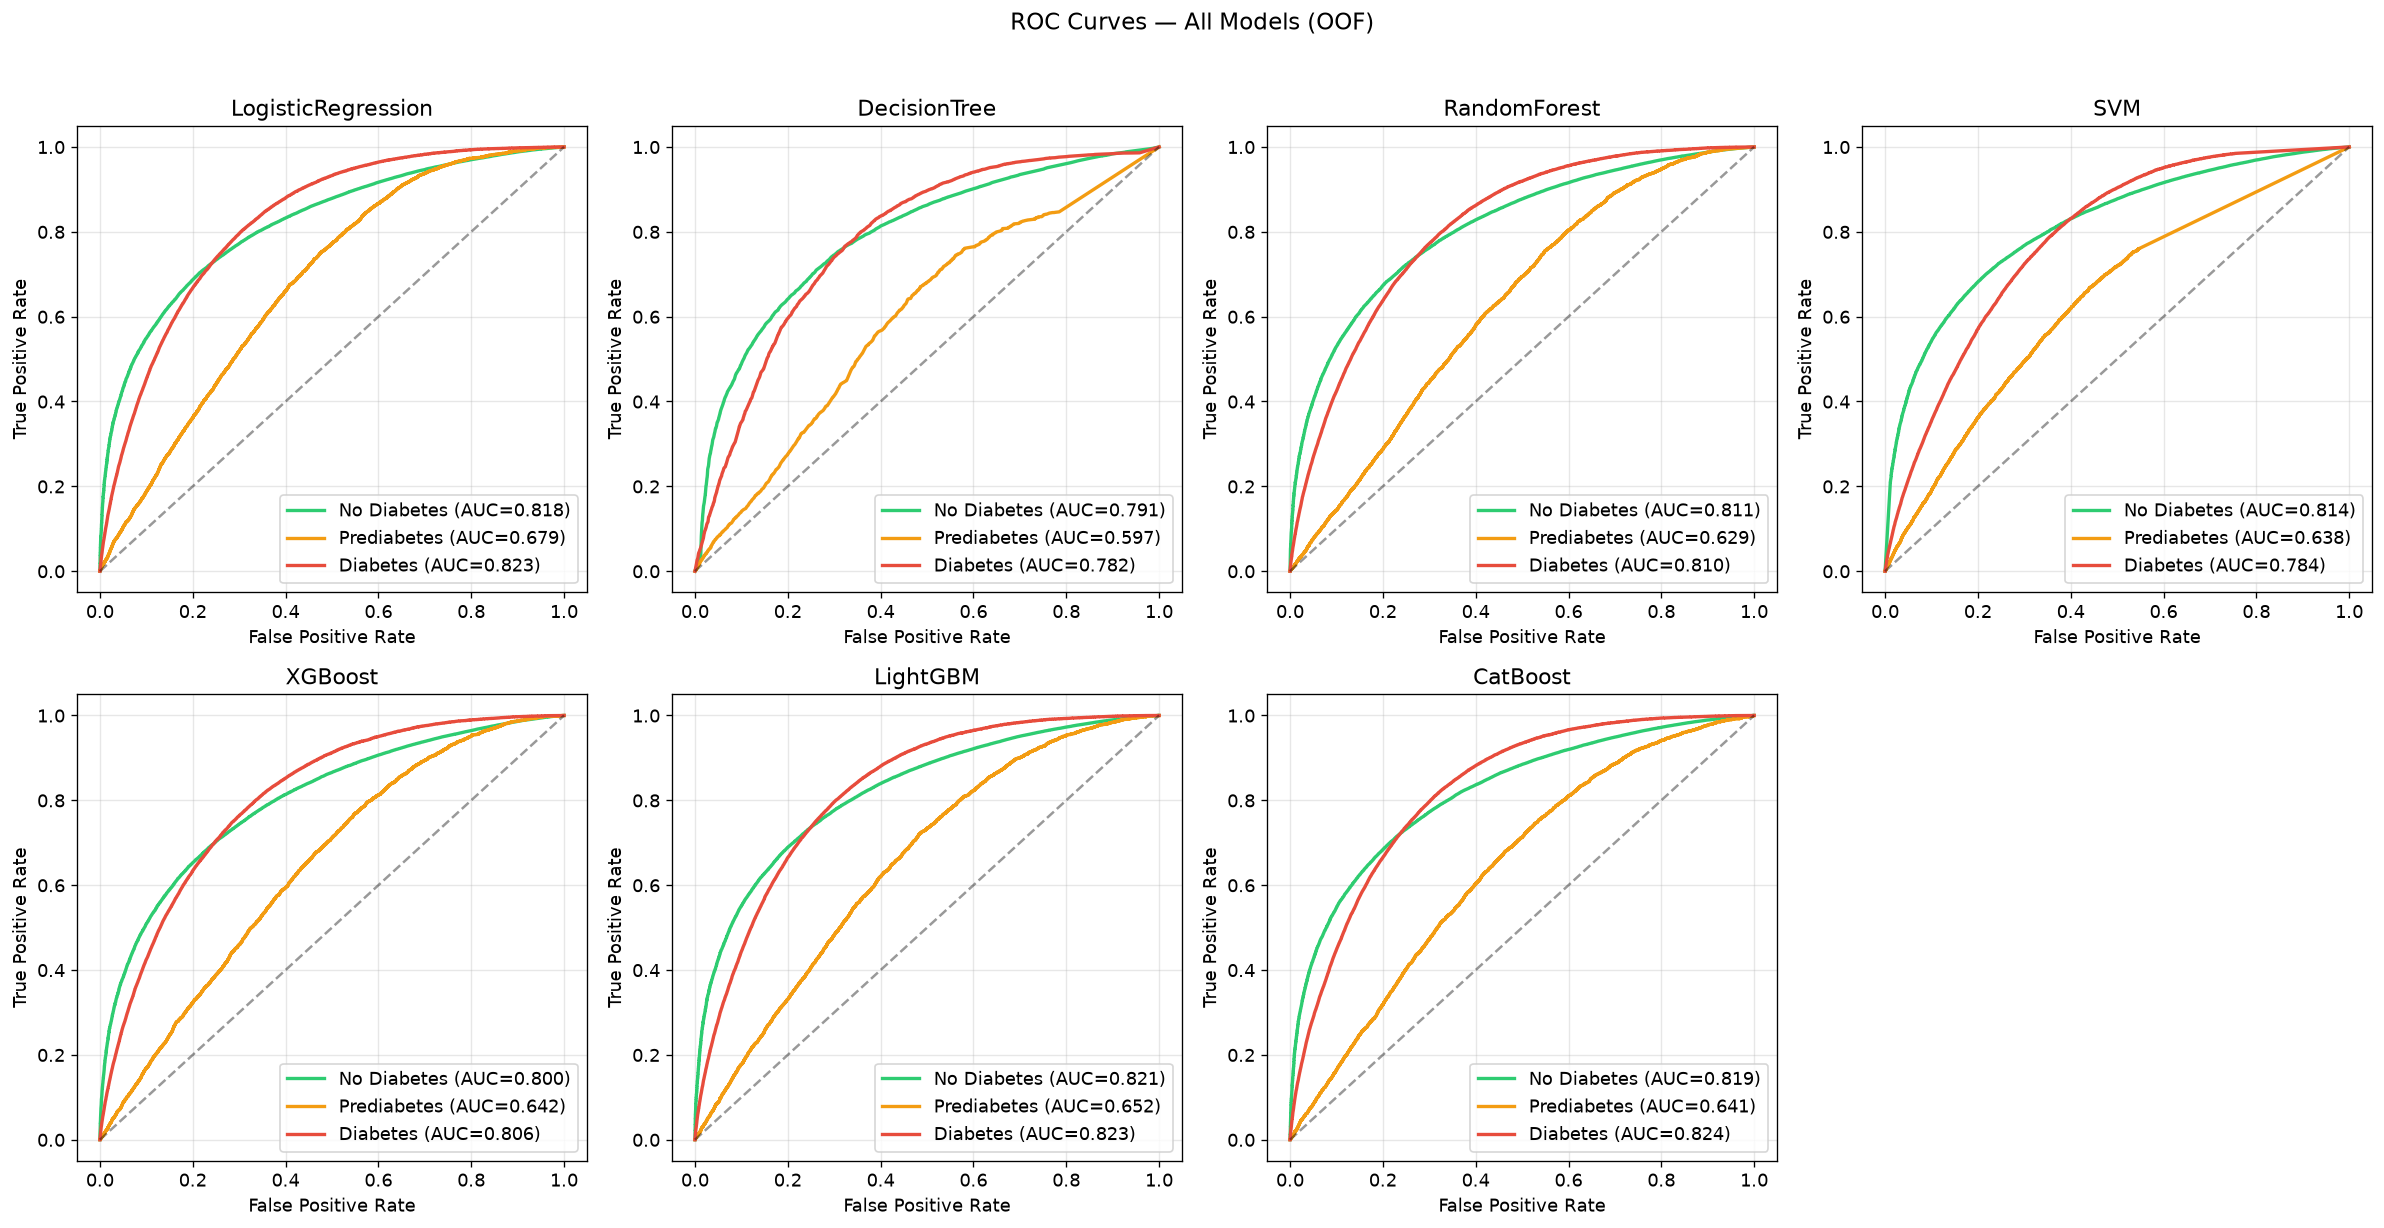

In [5]:
# ROC curves for all models
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for i, name in enumerate(MODEL_NAMES):
    prob = oof_df[[f"{name}_prob_{c}" for c in range(N_CLASSES)]].values
    plot_roc_curves(y_true, prob, title=f"{name}", ax=axes[i])
axes[-1].set_visible(False)
plt.suptitle("ROC Curves — All Models (OOF)", fontsize=14, y=1.02)
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "10_roc_all_models.png"))
plt.show()


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\10_pr_all_models.png


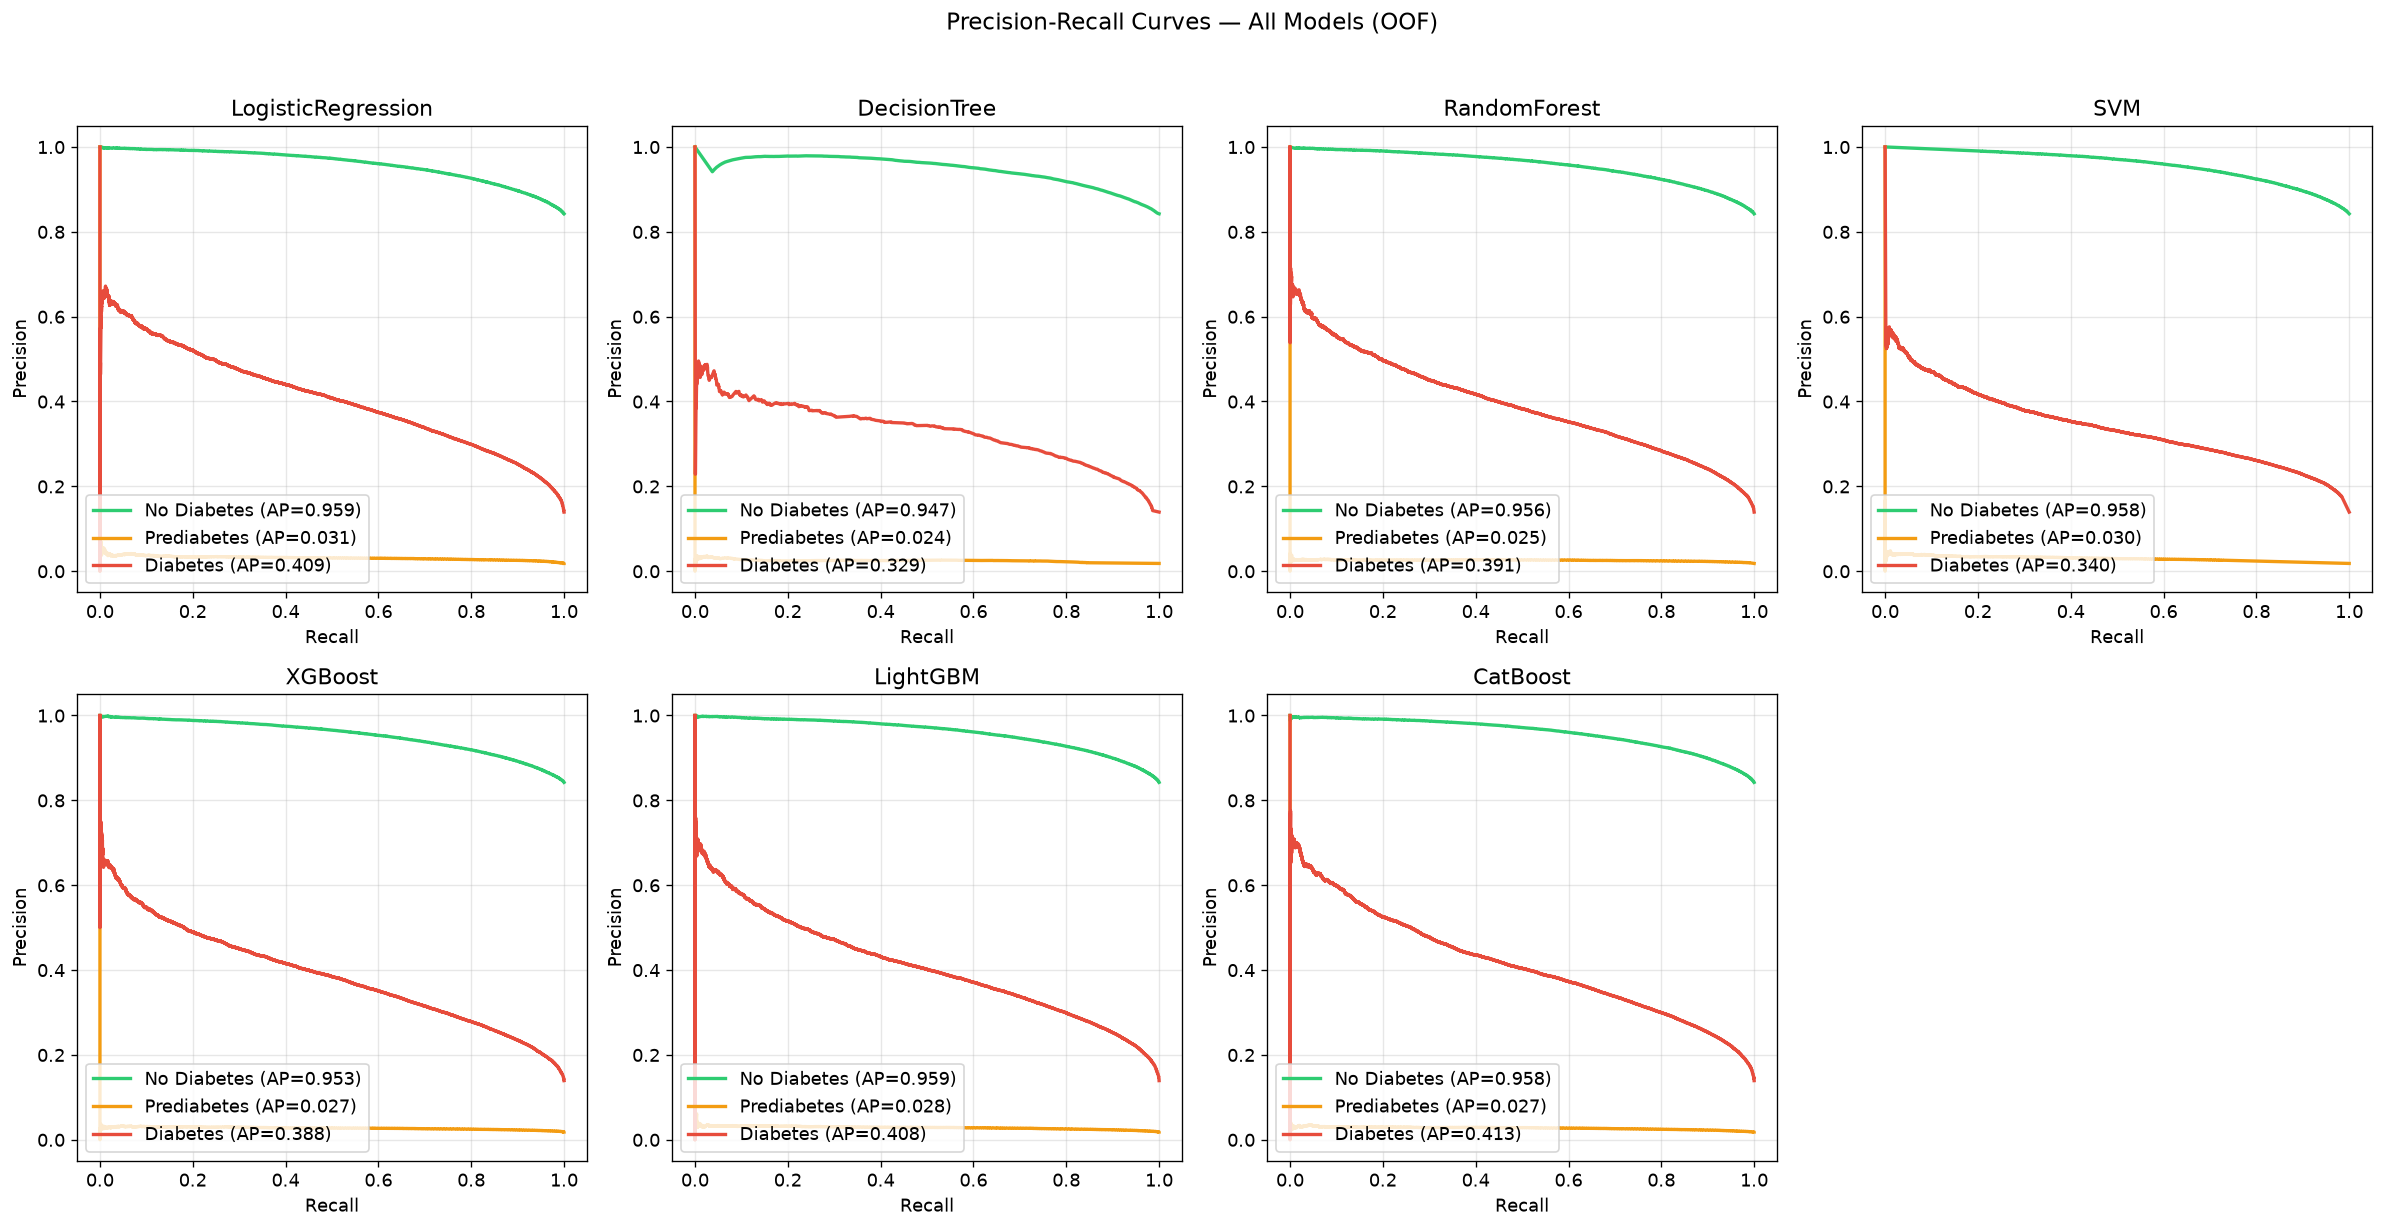

In [6]:
# PR curves for all models
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for i, name in enumerate(MODEL_NAMES):
    prob = oof_df[[f"{name}_prob_{c}" for c in range(N_CLASSES)]].values
    plot_pr_curves(y_true, prob, title=f"{name}", ax=axes[i])
axes[-1].set_visible(False)
plt.suptitle("Precision-Recall Curves — All Models (OOF)", fontsize=14, y=1.02)
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "10_pr_all_models.png"))
plt.show()


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\10_calibration_curves.png


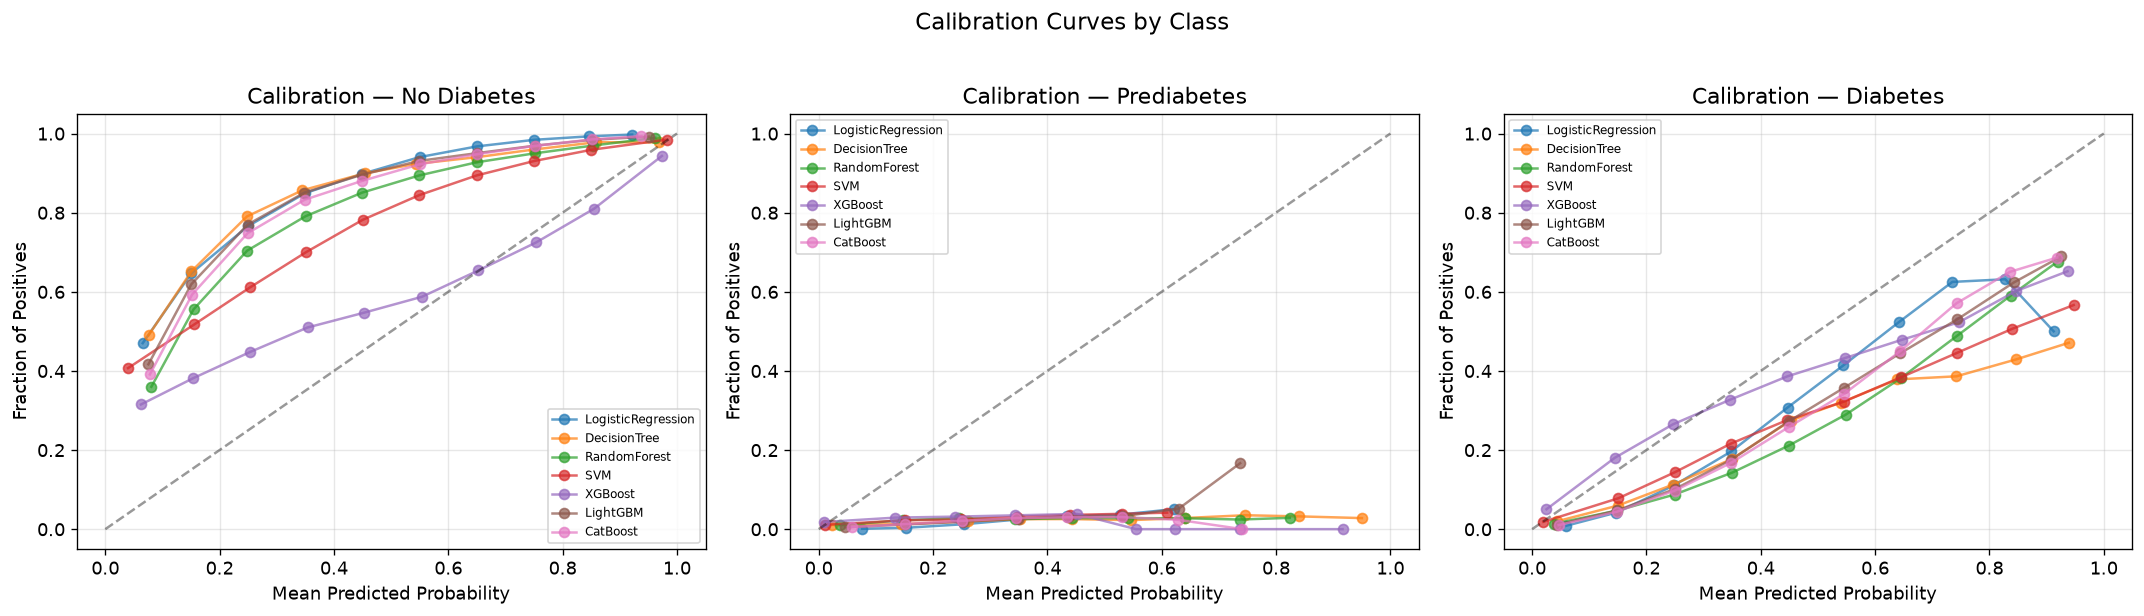

In [7]:
# Calibration curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for cls in range(N_CLASSES):
    y_bin = (y_true == cls).astype(int)
    for name in MODEL_NAMES:
        prob = oof_df[f"{name}_prob_{cls}"].values
        fraction_pos, mean_predicted = calibration_curve(y_bin, prob, n_bins=10, strategy="uniform")
        axes[cls].plot(mean_predicted, fraction_pos, marker='o', label=name, alpha=0.7)
    axes[cls].plot([0, 1], [0, 1], 'k--', alpha=0.4)
    axes[cls].set_xlabel("Mean Predicted Probability")
    axes[cls].set_ylabel("Fraction of Positives")
    axes[cls].set_title(f"Calibration — {CLASS_NAMES[cls]}")
    axes[cls].legend(fontsize=7)

plt.suptitle("Calibration Curves by Class", fontsize=14, y=1.02)
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "10_calibration_curves.png"))
plt.show()


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\10_per_class_recall_heatmap.png


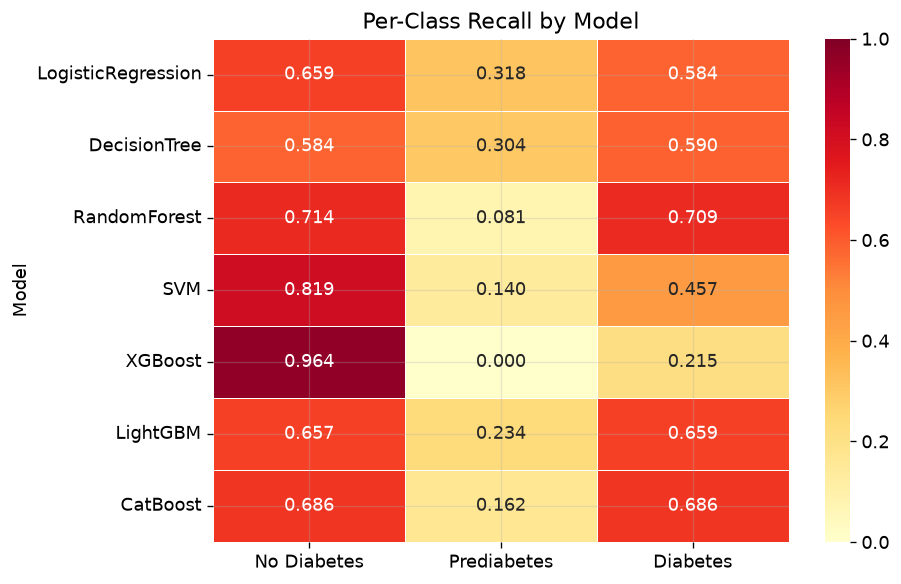

In [8]:
# Per-class recall heatmap
recall_data = {}
for name in MODEL_NAMES:
    recall_data[name] = [metrics_df.loc[name, f"Recall_Class{c}"] for c in range(N_CLASSES)]

recall_heatmap = pd.DataFrame(recall_data, index=CLASS_NAMES).T

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(recall_heatmap, annot=True, fmt=".3f", cmap="YlOrRd", ax=ax,
            vmin=0, vmax=1, linewidths=0.5)
ax.set_title("Per-Class Recall by Model")
ax.set_ylabel("Model")
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "10_per_class_recall_heatmap.png"))
plt.show()


## 10.4 Conclusion

**Evaluation summary:**

1. **Gradient boosting models** (XGBoost, LightGBM, CatBoost) consistently outperform simpler methods.
2. **SVM** is competitive but slower to train.
3. **Prediabetes (Class 1)** has low recall across all models — this is the hardest class.
4. **Calibration** varies — some models are overconfident for certain classes.
5. The best single model will be identified and compared against the proposed hybrid in Notebook 12.

**Note:** The hybrid model will be added to this comparison after Notebooks 11-12.

**Next:** Notebook 11 — Failure Analysis
